# ResNet‑56 na CIFAR‑10

## 1. Blok rezydualny i architektura

Ścieżka rezydualna $F$ wykonuje Conv → BatchNorm → ReLU → Conv → BatchNorm.
Wyjście bloku to $\operatorname{ReLU}(F(x)+s(x))$. Skrót $s(x)$ jest identycznością
w obrębie etapu. Przy zmianie rozdzielczości skrót typu A zachowuje co drugą
pozycję na obu osiach przestrzennych i dopełnia nowe kanały zerami.

| Część | Operacja | Wyjście bez wymiaru batcha |
|---|---|---|
| Stem | Conv 3×3, BN, ReLU | 16×32×32 |
| Etap 1 | 9 bloków rezydualnych | 16×32×32 |
| Etap 2 | 9 bloków, pierwszy ze stride 2 | 32×16×16 |
| Etap 3 | 9 bloków, pierwszy ze stride 2 | 64×8×8 |
| Klasyfikator | Global Average Pooling, Linear | 10 logitów |

Głębokość wynosi $1+3\cdot9\cdot2+1=56$ warstw z wagami.
Entropia krzyżowa w PyTorch przyjmuje logity i wewnętrznie wykonuje log-softmax.

## 2. Środowisko i konfiguracja

Domyślna konfiguracja wznawia zapisany eksperyment lub rozpoczyna trening w pustym
katalogu wyników. Ukończony checkpoint wystarcza do ponownego wykonania ewaluacji
i wykresów. Ten eksperyment zapisuje pliki w outputs/resnet56_cifar10.
Aby zacząć od losowych wag, ustaw nowy katalog wyników. Gdy trening
zostanie przerwany, wznowienie zacznie się od ostatniego zapisanego kroku.

In [1]:
import csv
import json
import platform
import time
import warnings
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
import torchvision
from PIL import Image
from torchvision.datasets import CIFAR10


@dataclass(frozen=True)
class Config:
    seed: int = 42
    batch_size: int = 128
    learning_rate: float = 0.1
    lr_milestones: tuple[int, int] = (32_000, 48_000)
    total_steps: int = 64_000
    momentum: float = 0.9
    weight_decay: float = 0.0001
    use_bfloat16: bool = True
    use_cuda_graph: bool = True
    val_per_class: int = 500
    cutout_size: int = 16
    report_every: int = 1_000
    data_dir: str = "data"
    output_dir: str = "outputs/resnet56_cifar10"
    resume: bool = True


CFG = Config()
PROJECT = Path.cwd()
if (PROJECT / "ResNET 56" / "1512.03385v1.pdf").is_file():
    PROJECT = PROJECT / "ResNET 56"

if not torch.cuda.is_available():
    raise RuntimeError("Trening wymaga PyTorch z działającą obsługą CUDA.")

DEVICE = torch.device("cuda:0")
AMP = CFG.use_bfloat16 and torch.cuda.is_bf16_supported()
if not 0 <= CFG.cutout_size <= 32:
    raise ValueError("Rozmiar Cutout musi należeć do przedziału od 0 do 32 pikseli.")
if not 0 < CFG.val_per_class < 5_000:
    raise ValueError("Liczba przykładów walidacyjnych na klasę musi być między 1 a 4999.")
torch.manual_seed(CFG.seed)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.matmul.allow_tf32 = False

OUT = PROJECT / CFG.output_dir
OUT.mkdir(parents=True, exist_ok=True)
LAST_PATH = OUT / "last.pt"
if LAST_PATH.exists() and not CFG.resume:
    raise FileExistsError(f"{LAST_PATH} już istnieje. Zmień output_dir lub wznów trening.")

ENVIRONMENT = {
    "python": platform.python_version(),
    "torch": str(torch.__version__),
    "torchvision": torchvision.__version__,
    "cuda": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(DEVICE),
    "gpu_memory_gib": round(torch.cuda.get_device_properties(DEVICE).total_memory / 2**30, 2),
    "precision": "AMP BF16" if AMP else "FP32",
}

print(f"Urządzenie: {ENVIRONMENT['gpu']} ({ENVIRONMENT['gpu_memory_gib']:.2f} GiB)")
print(f"PyTorch {torch.__version__}, CUDA {torch.version.cuda}, trening {ENVIRONMENT['precision']}")
print(f"Katalog wyników: {OUT.relative_to(PROJECT)}")

Urządzenie: NVIDIA GeForce RTX 4070 SUPER (11.99 GiB)
PyTorch 2.7.1+cu128, CUDA 12.8, trening AMP BF16
Katalog wyników: outputs\resnet56_cifar10


## 3. Dane, Cutout i walidacja

Autorzy ResNet użyli podziału 45 000/5 000 do ustalenia liczby kroków, a wyniki w
tabeli 6 opisali dla modeli trenowanych na 50 000 obrazów.

Tutaj przed treningiem losujemy **po 500 przykładów z każdej klasy** na walidację
(ziarno podziału 42). Z pozostałych **45 000** przykładów uczymy wagi i obliczamy
średnią RGB dla każdej pozycji. **5 000** przykładów walidacyjnych służy do
monitorowania uczenia i wyboru checkpointu. Oficjalne **10 000** przykładów
testowych służy do końcowej oceny wybranego modelu.

**Własne decyzje dotyczące danych**

- Obrazy skalujemy do [0, 1] i odejmujemy średnią per piksel z 45 000 przykładów.
  Przed losowym cropem dopełniamy wyśrodkowane obrazy zerami o 4 piksele
  z każdej strony. Poziome odbicie stosujemy z prawdopodobieństwem 1/2.
- Do każdego augmentowanego obrazu dodajemy jedną maskę **Cutout 16×16**.
  Środek losujemy jednostajnie na obrazie, maskę przycinamy do jego granic,
  a zaznaczone piksele zerujemy we wszystkich kanałach. Rozmiar zaczerpnęliśmy
  z eksperymentów na CIFAR‑10 opisanych przez
  [DeVriesa i Taylor, sekcja 4.1](https://arxiv.org/abs/1708.04552).
- W walidacji i teście przetwarzamy oryginalny obraz w jednym przebiegu
  i odejmujemy tę samą średnią. Dane treningowe, losowanie cropu i Cutout są na GPU.
- Torchvision sprawdza sumy kontrolne w lokalnym katalogu data projektu ResNet‑56.
  Używa istniejącej kopii albo rozpakowuje lokalne archiwum CIFAR‑10. W razie
  braku archiwum pobiera je z oficjalnego źródła do tego samego katalogu.

In [2]:
def load_cifar10(root, *, train, download=False):
    with warnings.catch_warnings():
        # NumPy 2.4 ostrzega przy odczycie align=0 ze starszego pickle CIFAR-10.
        warnings.filterwarnings(
            "ignore",
            message=r"dtype\(\): align should be passed as Python or NumPy boolean but got \x60align=0\x60\.",
            category=np.exceptions.VisibleDeprecationWarning,
            module=r"^torchvision\.datasets\.cifar$",
        )
        return CIFAR10(root, train=train, download=download)


data_root = PROJECT / CFG.data_dir
raw_train = load_cifar10(data_root, train=True, download=True)

CLASS_NAMES = raw_train.classes
NUM_CLASSES = len(CLASS_NAMES)
assert raw_train.data.shape == (50_000, 32, 32, 3)
assert NUM_CLASSES == 10

targets = np.asarray(raw_train.targets)
split_rng = np.random.default_rng(CFG.seed)
train_parts, val_parts = [], []
for label in range(NUM_CLASSES):
    indices = split_rng.permutation(np.flatnonzero(targets == label))
    val_parts.append(indices[:CFG.val_per_class])
    train_parts.append(indices[CFG.val_per_class:])

train_indices = np.sort(np.concatenate(train_parts))
val_indices = np.sort(np.concatenate(val_parts))
TRAIN_COUNT, VAL_COUNT = len(train_indices), len(val_indices)
assert TRAIN_COUNT + VAL_COUNT == len(raw_train)
assert not np.intersect1d(train_indices, val_indices).size
assert np.all(np.bincount(targets[val_indices]) == CFG.val_per_class)
np.savez(OUT / "split_indices.npz", train=train_indices, validation=val_indices)
validation_examples = raw_train.data[[class_indices[0] for class_indices in val_parts]]

train_pixels = raw_train.data[train_indices]
pixel_mean = torch.from_numpy((train_pixels.mean(axis=0) / 255).astype(np.float32))
mean_gpu = pixel_mean.to(DEVICE)


def preprocess_eval_images(pixels):
    images = torch.as_tensor(pixels, device=DEVICE)
    return images.float().div_(255).sub_(mean_gpu).permute(0, 3, 1, 2)


train_labels = torch.as_tensor(targets[train_indices], device=DEVICE)
val_labels = torch.as_tensor(targets[val_indices], device=DEVICE)
val_images = preprocess_eval_images(raw_train.data[val_indices])
train_images = torch.zeros(
    (TRAIN_COUNT, 40, 40, 3),
    device=DEVICE,
    dtype=torch.bfloat16 if AMP else torch.float32,
)

for start in range(0, TRAIN_COUNT, 4096):
    end = min(start + 4096, TRAIN_COUNT)
    images = torch.as_tensor(train_pixels[start:end], device=DEVICE)
    train_images[start:end, 4:36, 4:36] = images.float().div_(255).sub_(mean_gpu)

del raw_train, train_pixels, images
crop_axis = torch.arange(32, device=DEVICE)
row_axis = crop_axis.view(1, -1, 1)
column_axis = crop_axis.view(1, 1, -1)
batch_image_shape = (CFG.batch_size, 1, 1)


def cutout_mask(centers, size):
    half = size // 2
    row_offsets = row_axis - centers[:, 0, None, None]
    column_offsets = column_axis - centers[:, 1, None, None]
    rows = (row_offsets >= -half) & (row_offsets < size - half)
    columns = (column_offsets >= -half) & (column_offsets < size - half)
    return rows & columns


def training_batch(indices):
    top = torch.randint(9, batch_image_shape, device=DEVICE)
    left = torch.randint(9, batch_image_shape, device=DEVICE)
    flip = torch.rand(batch_image_shape, device=DEVICE) < 0.5
    rows = top + row_axis
    cols = left + torch.where(flip, 31 - column_axis, column_axis)
    images = train_images[indices.view(batch_image_shape), rows, cols]
    if CFG.cutout_size:
        centers = torch.randint(32, (CFG.batch_size, 2), device=DEVICE)
        images.masked_fill_(cutout_mask(centers, CFG.cutout_size).unsqueeze(-1), 0)
    return images.permute(0, 3, 1, 2), train_labels[indices]


# Sprawdzamy pełny kwadrat i przycięcie maski przy górnej i lewej krawędzi.
masks = cutout_mask(torch.tensor([[16, 16], [0, 0]], device=DEVICE), 16)
assert masks.sum(dim=(1, 2)).tolist() == [256, 64]
assert masks[0, 8:24, 8:24].all()

print(f"CIFAR-10: {TRAIN_COUNT:,} obrazów treningowych i {VAL_COUNT:,} walidacyjnych")
print(f"Średnia treningowa: {tuple(pixel_mean.shape)} (H, W, C)")


CIFAR-10: 45,000 obrazów treningowych i 5,000 walidacyjnych
Średnia treningowa: (32, 32, 3) (H, W, C)


### Przykłady walidacyjne

Pokazujemy po jednym oryginalnym obrazie z każdej klasy. Wybieramy pierwszy
indeks z wylosowanej puli walidacyjnej danej klasy. Nazwa nad zdjęciem to
etykieta ze zbioru CIFAR-10.

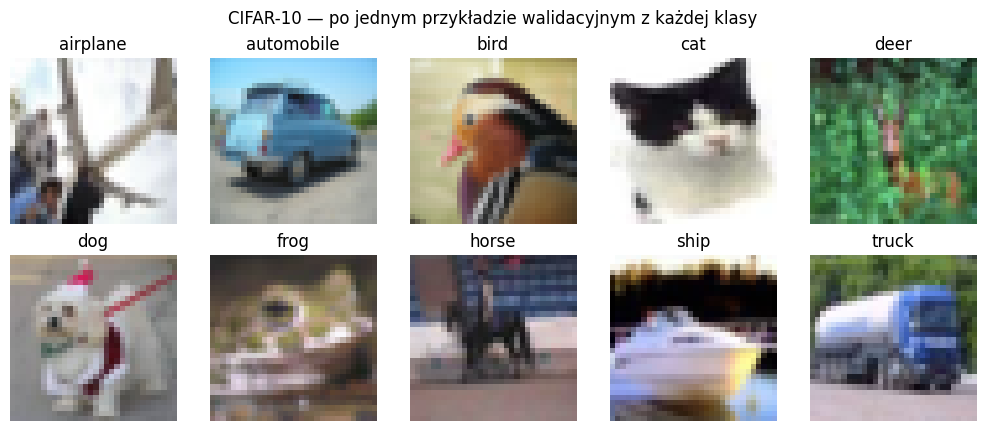

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.2), layout="constrained")
for ax, image, label in zip(axes.flat, validation_examples, CLASS_NAMES):
    ax.imshow(image, interpolation="nearest")
    ax.set_title(label)
    ax.axis("off")

fig.suptitle("CIFAR-10 — po jednym przykładzie walidacyjnym z każdej klasy")
fig.savefig(OUT / "data_examples.png", dpi=160)
plt.show()

## 4. Implementacja i kontrola modelu

Własne decyzje implementacyjne obejmują symetryczne dopełnienie kanałów w
skrócie A, stride 2 od pozycji (0, 0) i padding 1 w konwolucjach 3×3.
Konwolucje z BN mają wyłączony bias. Inicjalizację He dla konwolucji
realizujemy jako rozkład normalny w trybie fan-in. W BN stosujemy
$\gamma=1$, $\beta=0$, epsilon 0,00001 i momentum 0,1 w konwencji PyTorch.
Klasyfikator ma inicjalizację Kaiminga dla liniowej aktywacji i zerowy bias.

In [4]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.stride = stride
        self.extra_channels = out_channels - in_channels
        self.conv1 = nn.Conv2d(
            in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False,
        )
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

    def shortcut(self, x):
        if self.stride == 1 and self.extra_channels == 0:
            return x
        x = x[:, :, ::self.stride, ::self.stride]
        left = self.extra_channels // 2
        return F.pad(x, (0, 0, 0, 0, left, self.extra_channels - left))

    def forward(self, x):
        residual = self.relu(self.bn1(self.conv1(x)))
        residual = self.bn2(self.conv2(residual))
        return self.relu(residual + self.shortcut(x))


class ResNet56(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
        )
        self.stage1 = self._make_stage(16, 16, stride=1)
        self.stage2 = self._make_stage(16, 32, stride=2)
        self.stage3 = self._make_stage(32, 64, stride=2)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(64, num_classes)
        self._initialize_weights()

    @staticmethod
    def _make_stage(in_channels, out_channels, stride):
        blocks = [ResidualBlock(in_channels, out_channels, stride)]
        blocks.extend(ResidualBlock(out_channels, out_channels) for _ in range(8))
        return nn.Sequential(*blocks)

    def _initialize_weights(self):
        for layer in self.modules():
            if isinstance(layer, nn.Conv2d):
                nn.init.kaiming_normal_(layer.weight, mode="fan_in", nonlinearity="relu")
            elif isinstance(layer, nn.BatchNorm2d):
                nn.init.ones_(layer.weight)
                nn.init.zeros_(layer.bias)
        nn.init.kaiming_normal_(self.classifier.weight, mode="fan_in", nonlinearity="linear")
        nn.init.zeros_(self.classifier.bias)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        return self.classifier(self.pool(x).flatten(1))


with torch.random.fork_rng(devices=[]):
    torch.random.default_generator.manual_seed(123)
    check_model = ResNet56()
    x = torch.randn(2, 16, 32, 32, requires_grad=True)
    assert check_model.stage1[0].shortcut(x) is x
    block = check_model.stage2[0]
    shortcut = block.shortcut(x)
    assert shortcut.shape == (2, 32, 16, 16)
    torch.testing.assert_close(shortcut[:, 8:24], x[:, :, ::2, ::2])
    assert shortcut[:, :8].count_nonzero() == 0
    assert shortcut[:, 24:].count_nonzero() == 0

    with torch.no_grad():
        block.conv2.weight.zero_()
    torch.testing.assert_close(block(x), shortcut.relu())
    block(x).sum().backward()
    torch.testing.assert_close(x.grad[:, :, ::2, ::2], (x[:, :, ::2, ::2] > 0).float())

    n_layers = sum(isinstance(layer, (nn.Conv2d, nn.Linear)) for layer in check_model.modules())
    n_blocks = sum(isinstance(layer, ResidualBlock) for layer in check_model.modules())
    assert (n_layers, n_blocks) == (56, 27)
    with torch.no_grad():
        assert check_model(torch.randn(2, 3, 32, 32)).shape == (2, 10)

del check_model, x, block, shortcut
model = ResNet56(NUM_CLASSES).to(DEVICE, memory_format=torch.channels_last)
PARAMETERS = sum(p.numel() for p in model.parameters())
assert PARAMETERS == 853_018
print(f"Kontrole poprawności zaliczone. {n_layers} warstw, {n_blocks} bloków, {PARAMETERS:,} parametrów.")

Kontrole poprawności zaliczone. 56 warstw, 27 bloków, 853,018 parametrów.


## 5. Trening na CUDA

### SGD, gradient i learning rate

Trening wykorzystuje **mini-batch SGD** (stochastic gradient descent) z
momentum 0,9 i weight decay 0,0001. Przy każdym kroku bierzemy 128 obrazów
z losowej kolejności zbioru treningowego i augmentujemy je w locie.
Entropia krzyżowa w kodzie uśrednia stratę z tych 128 obrazów.
Wywołanie `loss.backward()` wyznacza gradient tej straty względem wag,
a `optimizer.step()` wykonuje jedną aktualizację. W pełnym batch gradient
descent jedna aktualizacja wymagałaby policzenia gradientu na wszystkich
45 000 obrazach. U nas mini-batch daje zmienne oszacowanie tego gradientu.

**Learning rate** $\eta$ to parametr SGD, który skaluje wielkość kroku.
Gradient opisuje, jak zmienia się strata przy zmianie wag, a momentum
uwzględnia historię gradientów.

Zachowujemy harmonogram z sekcji 4.2 artykułu He i in. Przez pierwsze
32 000 kroków $\eta = 0{,}1$, przez następne 16 000 kroków $\eta = 0{,}01$,
a przez ostatnie 16 000 kroków $\eta = 0{,}001$.

Opcja `fused=True` pozwala PyTorch połączyć operacje aktualizacji na GPU.
Tensor learning rate na GPU pozwala grafowi CUDA odczytywać bieżącą wartość
przy każdym kroku. Oba rozwiązania wykonują aktualizację SGD z momentum.

### Walidacja i wybór checkpointu

Co 1 000 aktualizacji mierzymy trafność i stratę na całych 5 000 obrazów
walidacyjnych w trybie ewaluacji, z ustalonymi statystykami BatchNorm.
Wybieramy checkpoint z najwyższą trafnością walidacyjną. Przy remisie wybieramy
wcześniejszy. Zbiór testowy odczytujemy po zakończeniu treningu i wyborze modelu.

**Własne decyzje treningowe i techniczne**

- Używamy jednego GPU. 128 oznacza rozmiar całego batcha. Ustawiamy ziarno 42.
  Każde przejście po zbiorze korzysta z nowej permutacji, a batch może zawierać
  końcówkę jednej i początek kolejnej permutacji.
- Weight decay stosujemy do wag konwolucji i klasyfikatora. Parametry BN i bias
  klasyfikatora mają zerowy weight decay.
- Zapisujemy stan i metryki co 1 000 aktualizacji. Ostatni checkpoint zawiera
  parametry modelu, stan optymalizatora, stan losowania na CUDA i pozycję w
  permutacji oraz kopię najlepszego modelu według walidacji. Na innym sprzęcie lub
  przy innych bibliotekach wyniki mogą się różnić.

In [5]:
criterion = nn.CrossEntropyLoss()
decay, no_decay = [], []
for parameter in model.parameters():
    (decay if parameter.ndim > 1 else no_decay).append(parameter)

# Tensor CUDA sprawia, że ten sam graf odczytuje aktualny LR po każdej zmianie.
lr = torch.tensor(CFG.learning_rate, device=DEVICE)
optimizer = torch.optim.SGD(
    [{"params": decay}, {"params": no_decay, "weight_decay": 0.0}],
    lr=lr,
    momentum=CFG.momentum,
    weight_decay=CFG.weight_decay,
    fused=True,
)

run_config = asdict(CFG)
for key in ("resume", "use_cuda_graph", "data_dir", "output_dir"):
    run_config.pop(key)

history = []
best_val_accuracy = -1.0
best_step = 0
best_model = None
completed_steps = 0
training_seconds = 0.0
peak_allocated_bytes = 0
peak_reserved_bytes = 0
order = torch.empty(0, dtype=torch.long, device=DEVICE)
position = 0

if LAST_PATH.exists():
    checkpoint = torch.load(LAST_PATH, map_location="cpu", weights_only=True)
    if checkpoint["config"] != run_config or checkpoint["precision"] != ENVIRONMENT["precision"]:
        raise ValueError("Ustawienia nie odpowiadają checkpointowi. Wybierz nowy output_dir.")
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    for group in optimizer.param_groups:
        group["lr"] = lr
    torch.cuda.set_rng_state(checkpoint["cuda_rng"], DEVICE)
    order = checkpoint["order"].to(DEVICE)
    position = checkpoint["position"]
    completed_steps = checkpoint["completed_steps"]
    training_seconds = checkpoint["training_seconds"]
    peak_allocated_bytes = checkpoint["peak_allocated_bytes"]
    peak_reserved_bytes = checkpoint["peak_reserved_bytes"]
    history = checkpoint["history"]
    best_val_accuracy = checkpoint["best_val_accuracy"]
    best_step = checkpoint["best_step"]
    best_model = checkpoint["best_model"]
    del checkpoint
    print(f"Wczytano checkpoint po {completed_steps:,} aktualizacjach.")


def next_indices():
    global order, position
    end = position + CFG.batch_size
    if end <= order.numel():
        indices = order[position:end]
        position = end
        return indices

    tail = order[position:]
    order = torch.randperm(TRAIN_COUNT, device=DEVICE)
    position = CFG.batch_size - tail.numel()
    return torch.cat((tail, order[:position]))


def update(indices):
    optimizer.zero_grad(set_to_none=True)
    images, labels = training_batch(indices)
    with torch.autocast("cuda", dtype=torch.bfloat16, enabled=AMP, cache_enabled=False):
        logits = model(images)
        loss = criterion(logits, labels)
    loss.backward()
    optimizer.step()
    correct = logits.detach().argmax(1).eq(labels).sum()
    return torch.stack((loss.detach(), correct))


@torch.inference_mode()
def validation_metrics():
    was_training = model.training
    model.eval()
    try:
        totals = torch.zeros(2, device=DEVICE)
        for images, labels in zip(val_images.split(CFG.batch_size), val_labels.split(CFG.batch_size)):
            logits = model(images)
            loss = F.cross_entropy(logits, labels, reduction="sum")
            correct = logits.argmax(1).eq(labels).sum()
            totals.add_(torch.stack((loss, correct)))
        loss_sum, correct_sum = totals.tolist()
        return loss_sum / VAL_COUNT, correct_sum / VAL_COUNT
    finally:
        model.train(was_training)


def atomic_save(payload, path):
    temporary = path.with_suffix(".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)


def write_json(path, payload):
    path.write_text(json.dumps(payload, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")


def write_history():
    if history:
        with (OUT / "history.csv").open("w", newline="", encoding="utf-8") as output:
            writer = csv.DictWriter(output, fieldnames=history[0].keys())
            writer.writeheader()
            writer.writerows(history)

In [6]:
if completed_steps < CFG.total_steps:
    model.train()
    torch.cuda.reset_peak_memory_stats(DEVICE)
    start_time = time.perf_counter()
    previous_seconds = training_seconds
    calculations = torch.zeros(2, device=DEVICE)
    count = 0
    graph = None
    graph_indices = None
    graph_result = None
    warmup_stream = torch.cuda.Stream()
    interval_start = completed_steps
    learning_rate = None

    print(f"Trening: {completed_steps:,} → {CFG.total_steps:,} aktualizacji.", flush=True)
    for step in range(completed_steps, CFG.total_steps):
        new_lr = CFG.learning_rate * 0.1 ** sum(step >= mark for mark in CFG.lr_milestones)
        if new_lr != learning_rate:
            lr.fill_(new_lr)
            learning_rate = new_lr

        indices = next_indices()
        if CFG.use_cuda_graph and step < interval_start + 3:
            warmup_stream.wait_stream(torch.cuda.current_stream())
            with torch.cuda.stream(warmup_stream):
                batch_result = update(indices)
            torch.cuda.current_stream().wait_stream(warmup_stream)
        elif CFG.use_cuda_graph:
            if graph is None:
                graph_indices = indices.clone()
                graph = torch.cuda.CUDAGraph()
                with torch.cuda.graph(graph):
                    graph_result = update(graph_indices)
            else:
                graph_indices.copy_(indices)
            graph.replay()
            batch_result = graph_result
        else:
            batch_result = update(indices)

        calculations.add_(batch_result)
        count += 1
        completed_steps = step + 1
        if completed_steps % CFG.report_every and completed_steps != CFG.total_steps:
            continue

        loss_total, correct_total = calculations.tolist()
        val_loss, val_accuracy = validation_metrics()
        if not np.isfinite([loss_total, val_loss]).all():
            raise FloatingPointError(f"Nieskończony loss po kroku {completed_steps:,}.")
        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_step = completed_steps
            best_model = {name: value.detach().cpu() for name, value in model.state_dict().items()}
        training_seconds = previous_seconds + time.perf_counter() - start_time
        peak_allocated_bytes = max(peak_allocated_bytes, torch.cuda.max_memory_allocated(DEVICE))
        peak_reserved_bytes = max(peak_reserved_bytes, torch.cuda.max_memory_reserved(DEVICE))
        row = {
            "step": completed_steps,
            "learning_rate": learning_rate,
            "train_loss": loss_total / count,
            "train_accuracy": correct_total / (count * CFG.batch_size),
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "training_seconds": training_seconds,
        }
        history.append(row)
        atomic_save(
            {
                "config": run_config,
                "precision": ENVIRONMENT["precision"],
                "model": model.state_dict(),
                "optimizer": optimizer.state_dict(),
                "order": order,
                "position": position,
                "cuda_rng": torch.cuda.get_rng_state(DEVICE),
                "completed_steps": completed_steps,
                "training_seconds": training_seconds,
                "peak_allocated_bytes": peak_allocated_bytes,
                "peak_reserved_bytes": peak_reserved_bytes,
                "history": history,
                "best_val_accuracy": best_val_accuracy,
                "best_step": best_step,
                "best_model": best_model,
            },
            LAST_PATH,
        )
        write_history()
        print(
            f"{completed_steps:>6,}/{CFG.total_steps:,}  "
            f"lr={learning_rate:.3g}  train={row['train_accuracy']:.2%}  "
            f"val={val_accuracy:.2%}  val loss={val_loss:.4f}  "
            f"czas={training_seconds / 60:.1f} min",
            flush=True,
        )
        calculations.zero_()
        count = 0

    # Graf używa stałych adresów modelu i gradientów. Po treningu nie jest już potrzebny.
    del graph, graph_result, graph_indices, batch_result
    optimizer.zero_grad(set_to_none=True)
else:
    write_history()
    print(f"Trening zakończony wcześniej. Odtworzono historię {completed_steps:,} kroków.")

print(f"Najlepsza walidacja: {best_val_accuracy:.2%} (krok {best_step:,}).")

Trening: 0 → 64,000 aktualizacji.
 1,000/64,000  lr=0.1  train=30.40%  val=38.30%  val loss=1.7499  czas=0.2 min
 2,000/64,000  lr=0.1  train=51.18%  val=63.06%  val loss=1.0482  czas=0.4 min
 3,000/64,000  lr=0.1  train=64.85%  val=70.50%  val loss=0.8494  czas=0.6 min
 4,000/64,000  lr=0.1  train=71.73%  val=77.96%  val loss=0.6622  czas=0.8 min
 5,000/64,000  lr=0.1  train=75.35%  val=80.84%  val loss=0.5774  czas=1.0 min
 6,000/64,000  lr=0.1  train=77.91%  val=82.34%  val loss=0.5316  czas=1.2 min
 7,000/64,000  lr=0.1  train=79.61%  val=80.16%  val loss=0.5998  czas=1.4 min
 8,000/64,000  lr=0.1  train=80.91%  val=84.04%  val loss=0.4734  czas=1.6 min
 9,000/64,000  lr=0.1  train=81.92%  val=85.98%  val loss=0.4078  czas=1.8 min
10,000/64,000  lr=0.1  train=82.87%  val=80.98%  val loss=0.5932  czas=2.0 min
11,000/64,000  lr=0.1  train=83.56%  val=85.84%  val loss=0.4072  czas=2.2 min
12,000/64,000  lr=0.1  train=84.23%  val=83.16%  val loss=0.5341  czas=2.4 min
13,000/64,000  lr=

## 6. Krzywe uczenia

Trafność treningowa jest średnią z augmentowanych batchy zebranych w trakcie
1 000 aktualizacji wag. Trafność walidacyjna jest wynikiem na odłożonych
obrazach bez augmentacji, obliczonym przy jednym stanie wag po tych aktualizacjach.
Walidacja może więc mieć wyższą trafność niż trening, szczególnie z Cutout.

Linia kropkowana wskazuje checkpoint z najlepszą trafnością walidacyjną.
Linie przerywane oznaczają zmiany learning rate.

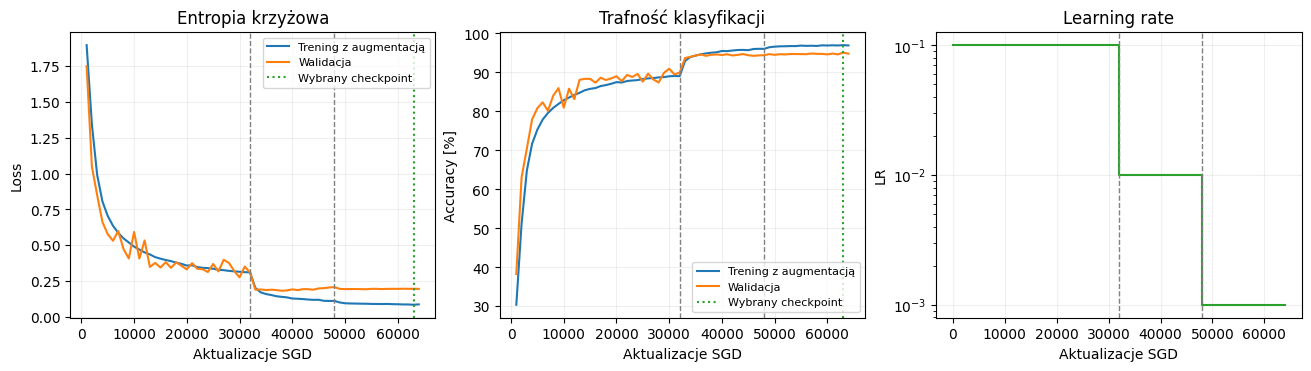

In [7]:
steps = [row["step"] for row in history]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), layout="constrained")
for split, label in (("train", "Trening z augmentacją"), ("val", "Walidacja")):
    axes[0].plot(steps, [row[f"{split}_loss"] for row in history], label=label)
    axes[1].plot(steps, [100 * row[f"{split}_accuracy"] for row in history], label=label)
for ax in axes[:2]:
    ax.axvline(best_step, linestyle=":", color="tab:green", label="Wybrany checkpoint")
    ax.legend(fontsize=8)
axes[2].step(
    [0, *steps],
    [CFG.learning_rate, *[row["learning_rate"] for row in history]],
    where="pre",
    color="tab:green",
)
axes[0].set(title="Entropia krzyżowa", ylabel="Loss")
axes[1].set(title="Trafność klasyfikacji", ylabel="Accuracy [%]")
axes[2].set(title="Learning rate", yscale="log", ylabel="LR")
for ax in axes:
    ax.set_xlabel("Aktualizacje SGD")
    ax.grid(alpha=0.2)
    for milestone in CFG.lr_milestones:
        ax.axvline(milestone, color="0.5", linestyle="--", linewidth=1)

fig.savefig(OUT / "learning_curves.png", dpi=160)
plt.show()

## 7. Test na 10 000 obrazów

Wczytujemy model wybrany wyłącznie według trafności walidacyjnej.
Każdy obraz przechodzi jeden raz przez model w oryginalnej rozdzielczości
32×32. Stosujemy wyłącznie odjęcie tej samej średniej co w treningu.
Raportujemy top‑1 accuracy, błąd testowy, entropię krzyżową oraz macro F1.
Wynik z tabeli 6 służy jako punkt odniesienia dla pojedynczego uruchomienia.

In [8]:
assert completed_steps == CFG.total_steps
assert best_model is not None
model.load_state_dict(best_model)
raw_test = load_cifar10(data_root, train=False, download=False)
assert len(raw_test) == 10_000
assert raw_test.classes == CLASS_NAMES
model.eval()
predictions = []
test_targets = torch.tensor(raw_test.targets)
loss_sum = 0.0

with torch.inference_mode():
    for start in range(0, len(raw_test), CFG.batch_size):
        end = min(start + CFG.batch_size, len(raw_test))
        images = preprocess_eval_images(raw_test.data[start:end])
        logits = model(images)
        labels = test_targets[start:end].to(DEVICE)
        loss_sum += F.cross_entropy(logits, labels, reduction="sum").item()
        predictions.append(logits.argmax(1).cpu())

test_predictions = torch.cat(predictions)
confusion = torch.bincount(
    NUM_CLASSES * test_targets + test_predictions,
    minlength=NUM_CLASSES**2,
).reshape(NUM_CLASSES, NUM_CLASSES)
assert confusion.sum().item() == 10_000
correct = confusion.diag()
precision = correct / confusion.sum(dim=0).clamp_min(1)
recall = correct / confusion.sum(dim=1).clamp_min(1)
f1 = 2 * precision * recall / (precision + recall).clamp_min(1e-12)

paper_accuracy = 0.9303
test_accuracy = correct.sum().item() / len(raw_test)
summary = {
    "config": run_config,
    "environment": ENVIRONMENT,
    "parameters": PARAMETERS,
    "train_samples": TRAIN_COUNT,
    "validation_samples": VAL_COUNT,
    "test_samples": len(raw_test),
    "completed_steps": completed_steps,
    "best_step": best_step,
    "best_val_accuracy": best_val_accuracy,
    "final_val_accuracy": history[-1]["val_accuracy"],
    "training_seconds": training_seconds,
    "peak_torch_allocated_gib": peak_allocated_bytes / 2**30,
    "peak_torch_reserved_gib": peak_reserved_bytes / 2**30,
    "test_correct": correct.sum().item(),
    "test_accuracy": test_accuracy,
    "test_error_rate": 1 - test_accuracy,
    "test_loss": loss_sum / len(raw_test),
    "macro_f1": f1.mean().item(),
    "paper_accuracy": paper_accuracy,
    "baseline_accuracy": 0.9263,
    "difference_to_baseline_pp": 100 * (test_accuracy - 0.9263),
    "accuracy_difference_pp": 100 * (test_accuracy - paper_accuracy),
}

write_json(OUT / "summary.json", summary)
atomic_save(
    {"model": best_model, "pixel_mean": pixel_mean, "classes": CLASS_NAMES, "step": best_step},
    OUT / "resnet56.pt",
)

print(f"Test accuracy: {test_accuracy:.2%} ({summary['test_correct']:,}/{len(raw_test):,})")
print(f"Błąd testowy: {summary['test_error_rate']:.2%}")
print(f"Test loss: {summary['test_loss']:.4f}, macro F1: {summary['macro_f1']:.4f}")
print(f"Różnica względem tabeli 6: {summary['accuracy_difference_pp']:+.2f} p.p.")
print(f"Różnica względem poprzedniego eksperymentu: {summary['difference_to_baseline_pp']:+.2f} p.p.")
print(
    f"Trening: {training_seconds / 60:.1f} min, "
    f"szczyt alokacji PyTorch: {summary['peak_torch_allocated_gib']:.2f} GiB, "
    f"szczyt rezerwacji: {summary['peak_torch_reserved_gib']:.2f} GiB."
)

Test accuracy: 93.80% (9,380/10,000)
Błąd testowy: 6.20%
Test loss: 0.2306, macro F1: 0.9380
Różnica względem tabeli 6: +0.77 p.p.
Różnica względem poprzedniego eksperymentu: +1.17 p.p.
Trening: 12.4 min, szczyt alokacji PyTorch: 0.76 GiB, szczyt rezerwacji: 0.90 GiB.


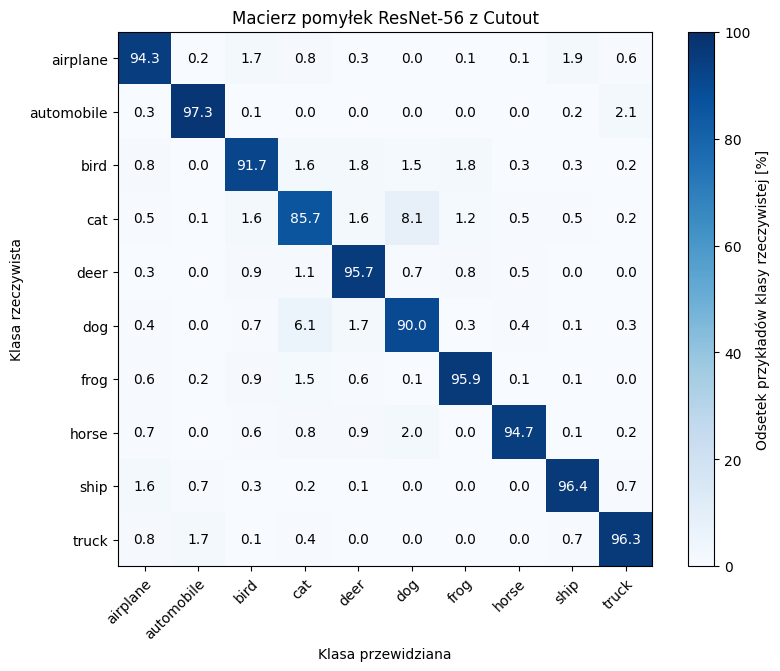

In [9]:
with (OUT / "per_class_metrics.csv").open("w", newline="", encoding="utf-8") as output:
    writer = csv.writer(output)
    writer.writerow(["class", "support", "precision", "recall", "f1"])
    for i, label in enumerate(CLASS_NAMES):
        writer.writerow(
            [label, confusion[i].sum().item(), precision[i].item(), recall[i].item(), f1[i].item()]
        )

row_percent = 100 * confusion / confusion.sum(1, keepdim=True)
fig, ax = plt.subplots(figsize=(8.3, 6.6), layout="constrained")
heatmap = ax.imshow(row_percent, cmap="Blues", vmin=0, vmax=100)
fig.colorbar(heatmap, ax=ax, label="Odsetek przykładów klasy rzeczywistej [%]")
ax.set(
    title="Macierz pomyłek ResNet-56 z Cutout",
    xticks=range(NUM_CLASSES),
    yticks=range(NUM_CLASSES),
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    xlabel="Klasa przewidziana",
    ylabel="Klasa rzeczywista",
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        value = row_percent[i, j].item()
        ax.text(j, i, f"{value:.1f}", va="center", ha="center", color="white" if value > 55 else "black")

fig.savefig(OUT / "confusion_matrix.png", dpi=160)
plt.show()

### Pierwsze 16 obrazów testowych

P pokazuje klasę przewidzianą przez model, a T to etykieta rzeczywista.
Zielony podpis oznacza poprawną predykcję, a czerwony pomyłkę.
Obrazy są w oryginalnej kolejności zbioru testowego.

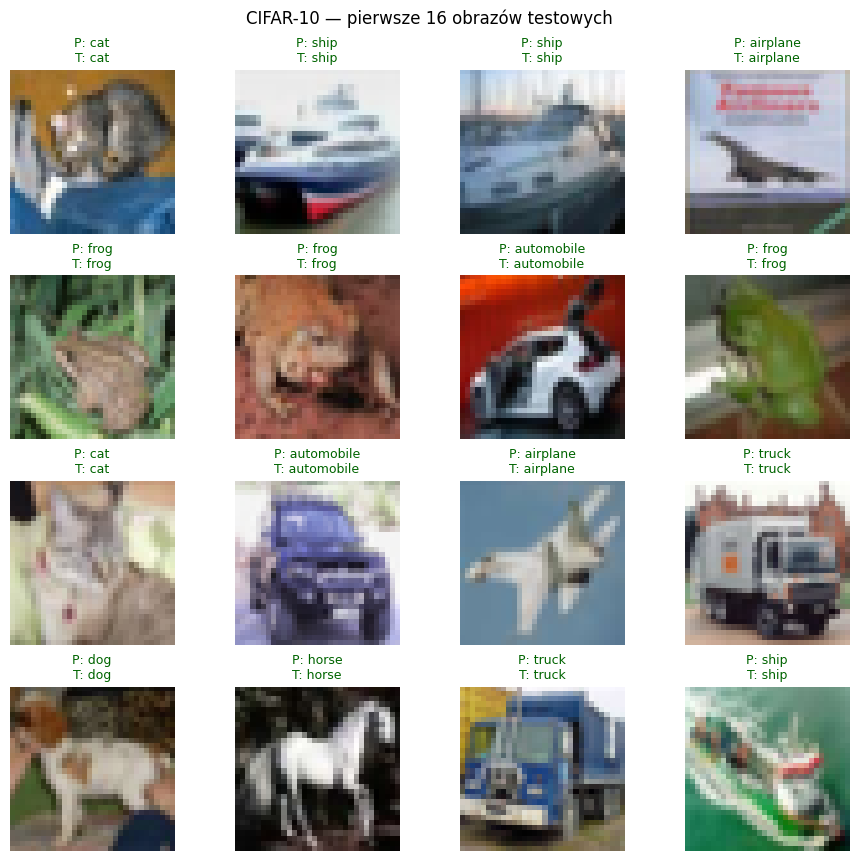

In [10]:
fig, axes = plt.subplots(4, 4, figsize=(9, 8.5), layout="constrained")
for index, ax in enumerate(axes.flat):
    predicted = test_predictions[index].item()
    target = test_targets[index].item()
    ax.imshow(raw_test.data[index], interpolation="nearest")
    ax.set_title(
        f"P: {CLASS_NAMES[predicted]}\nT: {CLASS_NAMES[target]}",
        color="darkgreen" if predicted == target else "firebrick",
        fontsize=9,
    )
    ax.axis("off")

fig.suptitle("CIFAR-10 — pierwsze 16 obrazów testowych")
fig.savefig(OUT / "test_examples.png", dpi=160)
plt.show()

## 8. Predykcja pojedynczego obrazu

Używamy jednego modelu ResNet-56 z checkpointu wybranego w walidacji. Funkcja
przyjmuje obraz PIL 32×32, konwertuje go do RGB i stosuje tę samą normalizację
co ewaluacja całego testu. Softmax zamienia logity na wyniki dla klas, z których
pokazujemy trzy najwyższe.

Dla własnego obrazu 32×32 można wywołać `predict_image(Image.open("obraz.png"))`.
Poniżej używamy pierwszego zdjęcia z CIFAR-10.

Klasa rzeczywista: cat
cat          >99.99%
dog          <0.01%
frog         <0.01%


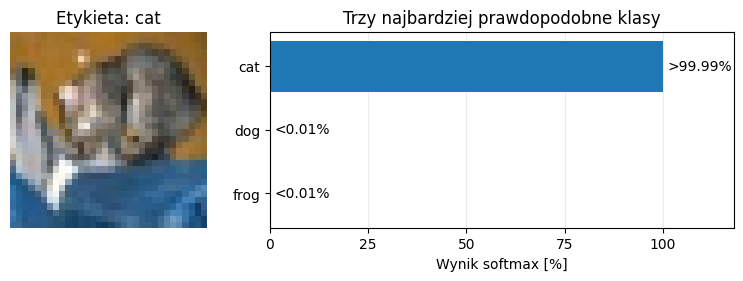

In [11]:
@torch.inference_mode()
def predict_image(image, top_k=3):
    if not isinstance(image, Image.Image):
        raise TypeError("Oczekiwany obraz PIL.Image.Image.")
    if image.size != (32, 32):
        raise ValueError("Oczekiwany rozmiar obrazu to 32×32 piksele.")
    if not isinstance(top_k, int) or isinstance(top_k, bool) or not 1 <= top_k <= NUM_CLASSES:
        raise ValueError(f"top_k musi być liczbą całkowitą od 1 do {NUM_CLASSES}.")

    pixels = np.array(image.convert("RGB"), dtype=np.uint8)
    model.eval()
    logits = model(preprocess_eval_images(pixels[None]))
    scores, indices = logits.double().softmax(dim=1)[0].topk(top_k)
    return [(CLASS_NAMES[index], score) for index, score in zip(indices.tolist(), scores.tolist())]


example = Image.fromarray(raw_test.data[0])
true_class = CLASS_NAMES[test_targets[0].item()]
top_predictions = predict_image(example)
print(f"Klasa rzeczywista: {true_class}")
probability_labels = []
for label, probability in top_predictions:
    if 0 < probability < 0.0001:
        formatted = "<0.01%"
    elif 0.9999 < probability < 1:
        formatted = ">99.99%"
    else:
        formatted = f"{probability:.2%}"
    probability_labels.append(formatted)
    print(f"{label:12} {formatted}")

labels, probabilities = zip(*top_predictions)
fig, (image_ax, probability_ax) = plt.subplots(
    1, 2, figsize=(7.5, 2.7), width_ratios=(1, 2), layout="constrained"
)
image_ax.imshow(example, interpolation="nearest")
image_ax.set_title(f"Etykieta: {true_class}")
image_ax.axis("off")

bars = probability_ax.barh(labels, [100 * p for p in probabilities], color="tab:blue")
probability_ax.invert_yaxis()
probability_ax.bar_label(bars, labels=probability_labels, padding=3)
probability_ax.set(xlim=(0, 118), xticks=(0, 25, 50, 75, 100), xlabel="Wynik softmax [%]")
probability_ax.set_title("Trzy najbardziej prawdopodobne klasy")
probability_ax.set_axisbelow(True)
probability_ax.grid(axis="x", alpha=0.25)

fig.savefig(OUT / "single_prediction.png", dpi=160)
plt.show()

## 9. Zapisane wyniki

- **resnet56.pt** zawiera wagi wybrane na walidacji, krok, średnią obrazu i kolejność klas.
- **last.pt** zawiera pełny stan do wznowienia i najlepszy model z walidacji.
- **history.csv** przechowuje metryki treningowe i walidacyjne z każdego pomiaru.
- **split_indices.npz** zawiera indeksy rozłącznych zbiorów treningowego i walidacyjnego.
- **summary.json**, **per_class_metrics.csv**, **learning_curves.png** i
  **confusion_matrix.png** dokumentują wynik i dane eksperymentu.
- **data_examples.png**, **test_examples.png** i **single_prediction.png**
  zawierają przykłady walidacyjne i wizualizacje predykcji.

Porównanie z artykułem wykorzystuje ten sam oficjalny zbiór testowy. Nasz protokół
obejmuje Cutout i 45 000 obrazów treningowych oraz wybór checkpointu na walidacji.